/tmp/ipython-input-3968908972.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('viridis', len(unique_labels))


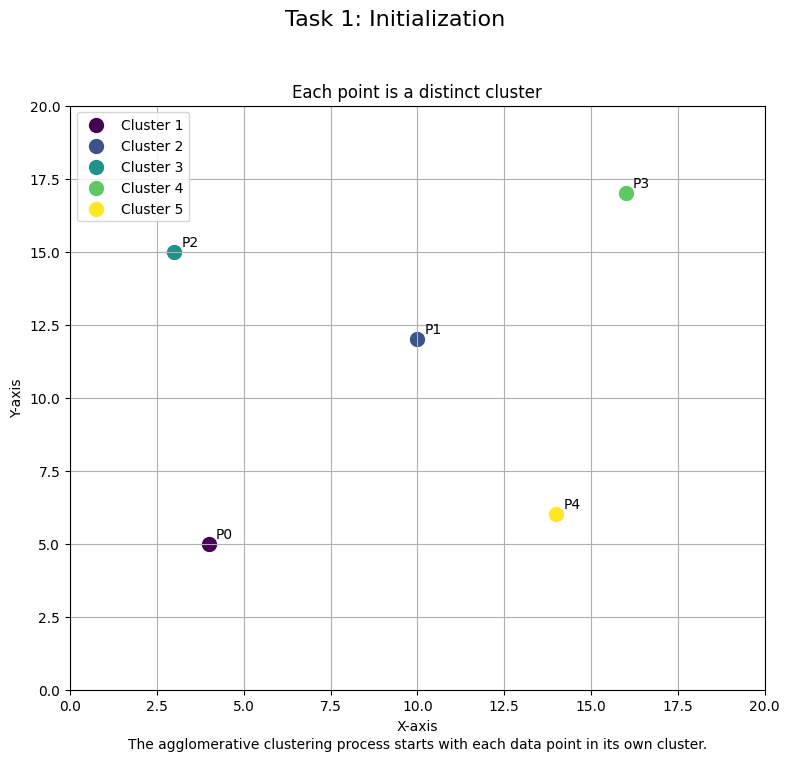

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# --- Main Script ---

# Sample data: 5 points in a 2D space (0 to 20) with pre-assigned values
X = np.array([[4, 5], [10, 12], [3, 15], [16, 17], [14, 6]], dtype=float)

# --- Task 1: Initialize ---
# Treat each of the N data points as a distinct cluster.
initial_labels = np.arange(len(X))

# --- Visualization for Task 1 ---
# Create a single figure to display the initial clusters
fig, ax = plt.subplots(figsize=(8, 8))
fig.suptitle('Task 1: Initialization', fontsize=16)

title = 'Each point is a distinct cluster'
step_text = 'The agglomerative clustering process starts with each data point in its own cluster.'
labels = initial_labels

unique_labels = np.unique(labels)
colors = plt.cm.get_cmap('viridis', len(unique_labels))

for i, label in enumerate(unique_labels):
    cluster_points = X[labels == label]
    ax.scatter(cluster_points[:, 0], cluster_points[:, 1],
               color=colors(i), label=f'Cluster {label+1}', s=100)
    # Add text labels for each point
    for point in cluster_points:
        ax.text(point[0] + 0.2, point[1] + 0.2, f'P{np.where((X == point).all(axis=1))[0][0]}')

ax.set_xlim(0, 20)
ax.set_ylim(0, 20)
ax.set_title(title, fontsize=12)
ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.grid(True)
ax.legend()
ax.text(0.5, -0.1, step_text, size=10, ha="center", transform=ax.transAxes)
# --- End of Visualization for Task 1 ---

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [10]:

# --- Task 2: Compute Proximity ---
# Calculate the distance matrix (N x N) between all pairs of clusters.
# We use Euclidean distance.
dist_matrix = squareform(pdist(X, 'euclidean'))
dist_text = "Task 2: Proximity Matrix (Euclidean Distances)\n\n" + np.array2string(dist_matrix, precision=2)
print(dist_matrix)


[[ 0.          9.21954446 10.04987562 16.97056275 10.04987562]
 [ 9.21954446  0.          7.61577311  7.81024968  7.21110255]
 [10.04987562  7.61577311  0.         13.15294644 14.2126704 ]
 [16.97056275  7.81024968 13.15294644  0.         11.18033989]
 [10.04987562  7.21110255 14.2126704  11.18033989  0.        ]]


In [20]:
# --- Task 3: Merge Clusters (Compute Linkage) ---
# Use scipy's linkage function to determine the merge order.
# 'single' method corresponds to finding the minimum distance between points in clusters.
Z = linkage(X, method='single', metric='euclidean')
print("Task 3: Linkage Matrix (Z)")
print("Format: [cluster_a, cluster_b, distance, num_points_in_new_cluster]")
print(np.array2string(Z, precision=2))


Task 3: Linkage Matrix (Z)
Format: [cluster_a, cluster_b, distance, num_points_in_new_cluster]
[[1.   4.   7.21 2.  ]
 [2.   5.   7.62 3.  ]
 [3.   6.   7.81 4.  ]
 [0.   7.   9.22 5.  ]]


In [21]:
print("Task 3 & 4: Step-wise Merge and Update")
num_points = len(X)
# A dictionary to keep track of the original points in each cluster
current_clusters = {i: [i] for i in range(num_points)}

for i, merge in enumerate(Z):
    cluster_a_id = int(merge[0])
    cluster_b_id = int(merge[1])
    distance = merge[2]

    # Get the points contained in each cluster being merged
    points_a = current_clusters.pop(cluster_a_id)
    points_b = current_clusters.pop(cluster_b_id)

    # The new cluster's ID is the number of points + the current step index
    new_cluster_id = num_points + i

    # Store the merged points under the new cluster ID
    current_clusters[new_cluster_id] = points_a + points_b

    # Create the text description for this merge step
    print(f"Step {i+1}:")
    print(f"  - Merge cluster {cluster_a_id} & {cluster_b_id} -> New Cluster {new_cluster_id}")
    print(f"  - Distance: {distance:.2f}")
    print(f"  - New cluster contains points: {sorted(current_clusters[new_cluster_id])}")
    print(f"  - Current active clusters: {sorted(list(current_clusters.keys()))}\n")


Task 3 & 4: Step-wise Merge and Update
Step 1:
  - Merge cluster 1 & 4 -> New Cluster 5
  - Distance: 7.21
  - New cluster contains points: [1, 4]
  - Current active clusters: [0, 2, 3, 5]

Step 2:
  - Merge cluster 2 & 5 -> New Cluster 6
  - Distance: 7.62
  - New cluster contains points: [1, 2, 4]
  - Current active clusters: [0, 3, 6]

Step 3:
  - Merge cluster 3 & 6 -> New Cluster 7
  - Distance: 7.81
  - New cluster contains points: [1, 2, 3, 4]
  - Current active clusters: [0, 7]

Step 4:
  - Merge cluster 0 & 7 -> New Cluster 8
  - Distance: 9.22
  - New cluster contains points: [0, 1, 2, 3, 4]
  - Current active clusters: [8]

